# Kalman Filter

In [8]:
import numpy as np
import matplotlib.pyplot as plt

With the histogram filter we described the distribution using histograms. For the Kalman filter we use Gaussians.
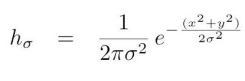

This is implemented in the code below:

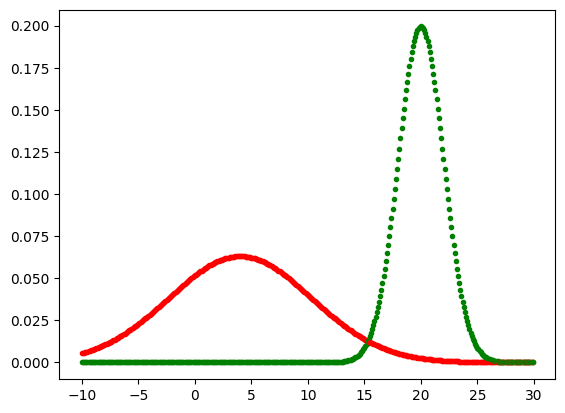

In [9]:
# Represent the robot's belief as a Gaussian (normal) distribution rather than
# a discrete histogram.
# Why Gaussians: a histogram stores one probability value per discrete bin, which
# works for small finite worlds. A Gaussian compresses the entire belief into just
# two numbers — mean u (the best position estimate) and variance sigma2 (how
# uncertain we are) — making the representation efficient and naturally suited to
# continuous quantities like physical position.
# Why the formula 1/sqrt(2π·σ²)·exp(-0.5·(x-u)²/σ²): this is the standard
# Gaussian probability density function. The leading normalisation factor ensures
# the curve integrates to 1 (a valid probability distribution). The exponential
# term creates the bell shape: probability peaks at x=u and falls off symmetrically,
# with the spread controlled by sigma2. Large sigma2 → wide, flat (uncertain) bell;
# small sigma2 → narrow, tall (confident) bell.
# Two Gaussians are plotted here to represent two independent pieces of information
# about the same unknown quantity that the Kalman filter will subsequently fuse.
def f(u, sigma2, x):
    return 1/np.sqrt(2*np.pi*sigma2) * np.exp(-0.5* ((x-u)**2/sigma2))

u = 4        # Mean for the first Gaussian
v = 20       # Mean for the second Gaussian
sigma2 = 40  # Variance for the first Gaussian
r2 = 4       # Variance for the second Gaussian

for x in np.arange(-10, 30, 0.1):
    plt.plot(x, f(u, sigma2, x),'.r')
    plt.plot(x, f(v, r2, x),'.g')

# Exercise 2a
We have here plotted two distributions. The Kalman filter makes its measurement update by combining the information from these two gaussians. 

Plot the final Gaussian after the measurement update based on the two Gaussians plotted above. Use the following formulas to do so:
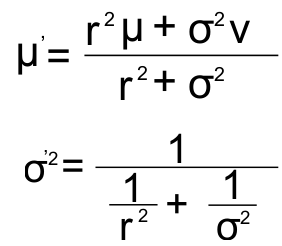

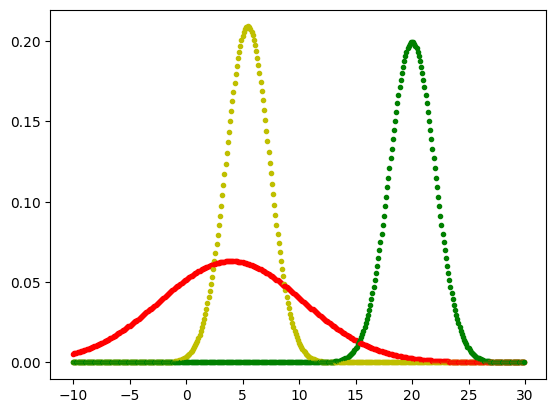

In [10]:
### Exercise 2a
### Compute and plot the Gaussian after measurement update

# Measurement update: fuse two independent Gaussian estimates into a single,
# more certain posterior Gaussian.
# Why the mean formula mu = (s2*u1 + s1*u2)/(s1+s2) is a variance-weighted
# average: each estimate contributes to the combined mean in proportion to
# how confident the other estimate is. A small variance (high confidence) in
# one Gaussian pulls the combined mean strongly toward that estimate; a large
# variance (low confidence) has proportionally less influence. The result always
# lies between the two input means, closer to whichever was more certain.
# Why the combined variance sigma is always smaller than both s1 and s2: fusing
# two independent pieces of information about the same quantity always increases
# certainty. The reciprocal formula 1/(1/s1 + 1/s2) — the harmonic mean of the
# variances — mathematically guarantees this. Combining beliefs can never make
# us less certain than either individual belief alone.
# The yellow curve plotted below is taller and narrower than both the red and
# green inputs, visually confirming the gain in certainty from the update step.

def update(u1, s1, u2, s2):
    mu    = (s2 * u1 + s1 * u2) / (s1 + s2)  # Weighted mean (weight = opposite variance)
    sigma = 1. / (1./s1 + 1./s2)              # Harmonic mean of variances — always smaller than both
    return mu, sigma

# Combine the two Gaussians defined above (red: wide/uncertain, green: narrow/confident)
# and plot the result in yellow
for x in np.arange(-10, 30, 0.1):
    mu, sigma = update(u, r2, v, sigma2)  # u/r2: prior (mean=4, var=4), v/sigma2: measurement (mean=20, var=40)
    plt.plot(x, f(mu, sigma, x), '.y')   # Yellow: combined belief — narrower than both
    plt.plot(x, f(u, sigma2, x), '.r')   # Red:    first Gaussian (wide)
    plt.plot(x, f(v, r2, x),    '.g')   # Green:  second Gaussian (narrow)

Notice that the resulting Gaussian has a higher peak than both of the others. This means that combining the two Gaussians we get a result that has less uncertainty than either of the original Gaussians.



 
 
 






Next we have the prediction or motion update. This one is simply made by adding the motion to the Gaussian mean and the motion variance to the Gaussian variance:


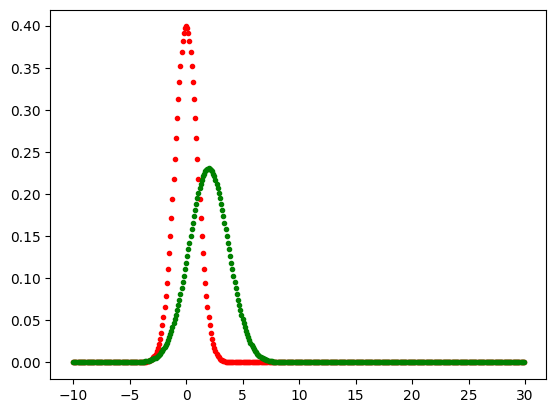

In [11]:
# Motion update (prediction step): project the current Gaussian belief forward
# in time by the robot's commanded motion.
# Why add the means: if the robot's best estimated position is u1 and it moves
# a distance u2, the new best-estimate position is simply u1 + u2. A physical
# displacement corresponds directly to a shift in the Gaussian's mean.
# Why add the variances: current position uncertainty (s2_1) and motion execution
# uncertainty (s2_2) are independent error sources. For independent Gaussian
# variables, variances add. This is the opposite of the measurement update: motion
# always increases uncertainty because we are extrapolating into the future without
# incorporating new evidence. The predict step spreads the belief; only a new
# measurement can concentrate it back again.
# The plot confirms this: the green post-move Gaussian is shifted to the right
# (mean advanced by the motion) and visibly flatter/wider (larger combined variance)
# compared to the original red Gaussian.
def predict(u1, s2_1, u2, s2_2):
    u  = u1 + u2      # Shift the mean by the motion distance
    s2 = s2_1 + s2_2  # Uncertainty grows: variances add
    return [u, s2]

u  = 0  # Starting position
s2 = 1  # Starting variance

motion        = 2  # Robot commanded to move 2 units
motion_sigma2 = 2  # Variance in how accurately it executes that motion

[u_pred, s2_pred] = predict(u, s2, motion, motion_sigma2)

x = np.arange(-10, 30, 0.1)
plt.plot(x, f(u,      s2,      x), '.r')  # Red:   belief before moving (narrow)
plt.plot(x, f(u_pred, s2_pred, x), '.g')  # Green: belief after moving (shifted right, wider)

# Exercise 2b
Combine the update function you made in the previous exercise with the predict function given above and plot all the Gaussians calculated using the measurements and motions given in the code below:

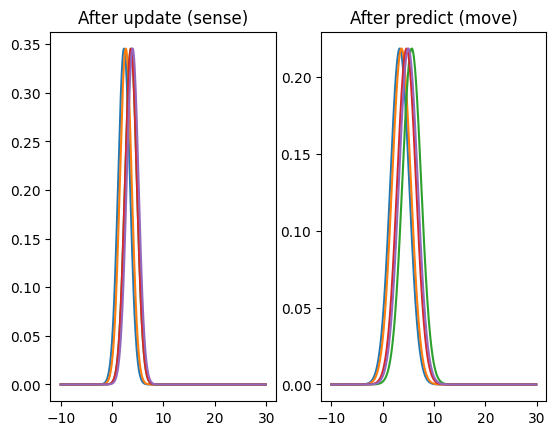

In [12]:
### Exercise 2b
# Apply the update and predict functions in an alternating loop across multiple
# time steps — the full 1D Kalman filter cycle expressed in scalar Gaussian form.
# Why alternate update then predict each step: update sharpens the belief by
# fusing in the current measurement; predict then shifts and widens it to account
# for the robot's next commanded motion before the following measurement arrives.
# This two-step cycle is the core engine of the Kalman filter, now repeated over
# an entire sequence rather than executed just once.
# Why store both post-update and post-predict results separately: plotting them
# side by side lets you directly compare the two complementary effects. The left
# subplot shows how each measurement immediately narrows the Gaussians (certainty
# gained); the right subplot shows how the following motion step re-widens them
# (certainty lost to dead reckoning). The contrast between the two reinforces
# the central intuition: sensing reduces uncertainty, moving increases it.
measurements   = [5, 6, 7, 9, 10]
measure_sigma  = 4   # Sensor noise variance (same for every measurement)
motion         = [1, 1, 2, 1, 1]
motion_sigma   = 2   # Motion noise variance

# NOTE: a proper sequential Kalman filter would carry a running prior from
# step to step (see Exercise 2c). Here each step is treated independently
# to demonstrate the shapes of the update and predict Gaussians in isolation.

x = np.arange(-10, 30, 0.1)
update_u,  update_s  = [], []
predict_u, predict_s = [], []

for i in range(len(measurements)):
    # Update: fuse the i-th measurement Gaussian with the i-th motion Gaussian
    # (illustrative — in a real filter the prior replaces the motion Gaussian)
    u, s = update(measurements[i], measure_sigma, motion[i], motion_sigma)
    update_u.append(u)
    update_s.append(s)

    # Predict: shift and widen the updated Gaussian by the motion
    u, s = predict(u, s, motion[i], motion_sigma)
    predict_u.append(u)
    predict_s.append(s)

# Left plot: Gaussians after each update step (should be narrow/confident)
plt.subplot(1, 2, 1)
plt.title('After update (sense)')
for i in range(len(update_u)):
    plt.plot(x, f(update_u[i], update_s[i], x))

# Right plot: Gaussians after each predict step (wider due to motion uncertainty)
plt.subplot(1, 2, 2)
plt.title('After predict (move)')
for i in range(len(predict_u)):
    plt.plot(x, f(predict_u[i], predict_s[i], x))

# Exercise 2c

It's now time to look at the more general equations of the Kalman filter. We would like to apply a Kalman filter for a robot moving in 1D. We would like to track and predict its position and its velocity. 

A quick summary of the variables:

**x** : The state matrix. Holds the state of the robot, which is its position and velocity.

**P** : The uncertainty of the state.

**u** : The external motion. In this case there will not be an external motion affecting the robot.

**F** : The transition matrix (or next state function). Used to predict the next state of the robot.

**H** : The observation matrix (or measurement function). Used to update the robot state.

**R** : The measurement uncertainty. 

**I** : Identity matrix.

You will now have to implement your own update and predict function using the formulas given here. All the matrices are given in the code below. 

When you multiply matrices together you can use [np.dot](https://docs.scipy.org/doc/numpy/reference/generated/numpy.dot.html). To get the inverse of a matrix, you can use [np.linalg.pinv](https://docs.scipy.org/doc/numpy/reference/generated/numpy.linalg.pinv.html). To get the transpose you can use [np.transpose](https://docs.scipy.org/doc/numpy/reference/generated/numpy.transpose.html).

The two equations written in black are the equations used for prediction and the rest are the equations used for updating.

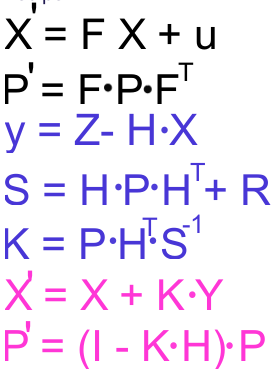

z:
[[1]]
X:
[[0.999001]
 [0.      ]]
P:
[[1000.999001 1000.      ]
 [1000.       1000.      ]]
z:
[[2.1]]
X:
[[3.19770369]
 [1.09880249]]
P:
[[4.99002494 2.99301795]
 [2.99301795 1.99501297]]
z:
[[2.9]]
X:
[[3.89974968]
 [0.95004978]]
P:
[[2.33189042 0.99916761]
 [0.99916761 0.49950058]]
z:
[[4.1]]
X:
[[5.04999975]
 [1.01010086]]
P:
[[1.49950037 0.4997502 ]
 [0.4997502  0.19987011]]
z:
[[5.]]
X:
[[6.0201078 ]
 [1.00010391]]
P:
[[1.09975015 0.29989007]
 [0.29989007 0.09995003]]
z:
[[5.9]]
X:
[[6.94015089]
 [0.9829499 ]]
P:
[[0.86651564 0.19994098]
 [0.19994098 0.0571192 ]]
z:
[[7.1]]
X:
[[8.01443254]
 [1.00007292]]
P:
[[0.71418372 0.14282145]
 [0.14282145 0.03570154]]
z:
[[8.1]]
X:
[[9.05728486]
 [1.00720218]]
P:
[[0.60706891 0.10711948]
 [0.10711948 0.02380202]]


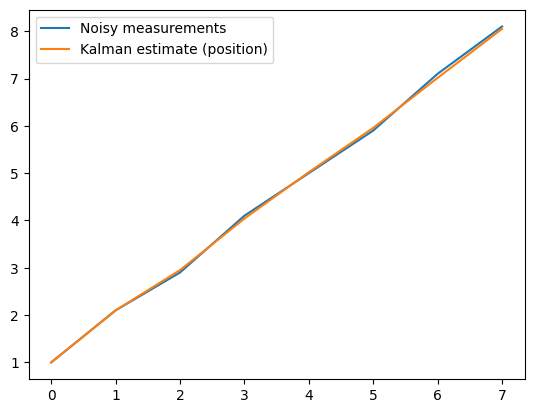

In [13]:
# Implement the full matrix-form Kalman filter for 1D localisation, tracking
# both position and velocity together in a single state vector.
# Why include velocity in the state alongside position: velocity lets the predict
# step extrapolate where the robot will be at the next timestep based on how fast
# it is currently moving. Without it, the filter would have no model of motion
# and would lose track of the robot between measurements. Crucially, velocity is
# never measured directly — the filter infers it from successive position readings.
# Why F = [[1,1],[0,1]] (the transition matrix): this encodes constant-velocity
# kinematics — new_position = old_position + old_velocity × Δt (one timestep
# unit here). The second row keeps velocity unchanged (no acceleration modelled).
# Representing this as a matrix lets the predict step advance the full state
# vector in a single np.dot call, no matter how many dimensions are added later.
# Why H = [[1, 0]] (the observation matrix): the sensor only reports position,
# not velocity. H projects the 2D state into 1D measurement space by selecting
# the position entry (index 0) and ignoring velocity (index 1). Any mismatch
# between state dimension and measurement dimension is handled here.
# Why P = diag(1000, 1000) initially: we genuinely don't know the robot's
# starting position or velocity. A huge covariance tells the filter "trust the
# first few measurements almost completely and correct the state rapidly", rather
# than stubbornly holding onto a confidently-wrong initial guess.
# How update() works step by step:
#   y = Z - H@x       Innovation: gap between the measurement and our prediction
#   S = H@P@Hᵀ + R    Innovation covariance (how uncertain is that gap?)
#   K = P@Hᵀ@S⁻¹      Kalman gain: weight to give the measurement vs. our model
#   x = x + K@y       Pull the state estimate toward the measurement by amount K
#   P = (I-K@H)@P     Uncertainty shrinks — new information was incorporated
# How predict() works step by step:
#   x = F@x + u       Advance state by one timestep using the motion model
#   P = F@P@Fᵀ        Propagate covariance through F (uncertainty grows)
# Why np.linalg.pinv instead of np.linalg.inv: the pseudo-inverse degrades
# gracefully if S is near-singular — a safe default inside a loop where
# numerical issues could otherwise crash the filter mid-sequence.

# --- Initial state ---
# State vector: [position, velocity]. Robot starts stationary at the origin.
x = np.array([[0],
              [0]])

# --- Initial uncertainty ---
# Covariance matrix P: diagonal entries are variances for position and velocity.
# Large values = very uncertain about starting state.
P = np.array([[1000, 0],
              [0,    1000]])

# --- External motion (control input) ---
# No external forces applied; the robot moves purely due to its own velocity.
u = np.array([[0],
              [0]])

# --- Transition matrix F ---
# Encodes the physics: new_position = position + velocity (one timestep).
# Velocity is assumed constant (no acceleration modelled).
#   [ 1  1 ]   [ pos ]   [ pos + vel ]
#   [ 0  1 ] × [ vel ] = [    vel    ]
F = np.array([[1, 1],
              [0, 1]])

# --- Observation matrix H ---
# We can only measure position directly, not velocity.
# Maps the 2D state to the 1D measurement space: z = H·x = position.
H = np.array([[1, 0]])

# --- Measurement noise R ---
# Scalar variance of the position sensor.
R = 1

# --- Identity matrix ---
I = np.array([[1, 0],
              [0, 1]])

# Noisy position measurements — robot moves ~1 unit per step
measurements = [1, 2.1, 2.9, 4.1, 5.0, 5.9, 7.1, 8.1]


def update(x, P, Z, H, R):
    """
    Kalman measurement update — fuse a new observation Z into the current
    state estimate x and covariance P.

    Steps:
      y = z - H·x        Innovation: how far off was our prediction?
      S = H·P·Hᵀ + R     Innovation covariance (uncertainty of the prediction in measurement space)
      K = P·Hᵀ·S⁻¹       Kalman gain: how much to trust the measurement vs. the model
      x = x + K·y        Nudge state toward the measurement, weighted by K
      P = (I - K·H)·P    Reduce uncertainty — we've gained information
    """
    y = Z - np.dot(H, x)                          # Innovation
    S = np.dot(H, np.dot(P, H.T)) + R             # Innovation covariance
    K = np.dot(P, np.dot(H.T, np.linalg.pinv(S))) # Kalman gain
    x = x + np.dot(K, y)                          # State update
    P = np.dot((I - np.dot(K, H)), P)             # Covariance update
    return [x, P]


def predict(x, P, F, u):
    """
    Kalman prediction step — project the state forward one timestep using
    the motion model F and control input u.

    Steps:
      x = F·x + u    Apply physics: advance position by current velocity
      P = F·P·Fᵀ     Propagate uncertainty (grows because we're extrapolating)

    Note: a full implementation would add process noise Q here (P = F·P·Fᵀ + Q),
    but Q=0 is assumed (perfect motion model).
    """
    x = np.dot(F, x) + u          # Predict next state
    P = np.dot(F, np.dot(P, F.T)) # Predict next covariance
    return [x, P]


### Main Kalman filter loop ###
# Each iteration: update (sense) then predict (move).
# After each predict, P should shrink and x should converge toward the true position.
states = []
for n in range(len(measurements)):
    z = np.array([[measurements[n]]])  # Wrap scalar measurement into column vector

    [x, P] = update(x, P, z, H, R)   # Fuse measurement into state
    states.append(x)                  # Record state after sensing
    [x, P] = predict(x, P, F, u)     # Project state forward to next timestep

    print('z:'); print(z)
    print('X:'); print(x)   # Notice velocity being inferred from position changes
    print('P:'); print(P)   # Notice P shrinking — filter becomes more confident

states = np.array(states)
plt.plot(measurements,           label='Noisy measurements')
plt.plot(states[:, 0, 0],        label='Kalman estimate (position)')
plt.legend()

Notice how the uncertainty **P** gets smaller and the predicted states gets more accurate than the actual measurements.

# Exercise 2d
Extent the previous matrices such that the robot can move in 2D. The update and predict functions don't have to be changed, only the matrices. For example the state matrix will now have to hold both the position and velocity in both the x- and y-direction: 


(7, 4, 1)


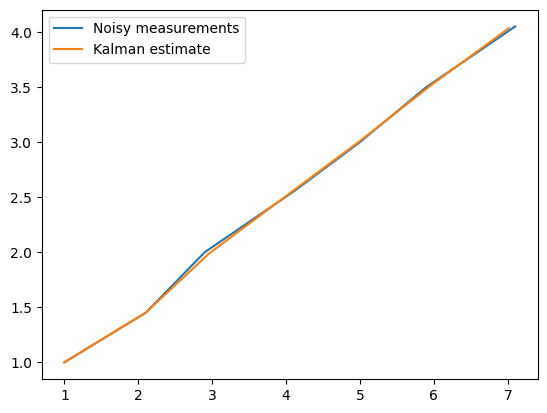

In [14]:
# Extend the matrix Kalman filter from 1D to 2D tracking by enlarging the
# matrices — the update() and predict() functions themselves need no changes.
# Why the state vector grows to [x_pos, x_vel, y_pos, y_vel]: each spatial axis
# needs its own position and velocity tracked independently. Interleaving the
# x and y components (rather than grouping all positions first) keeps each axis's
# pair of variables adjacent, which maps cleanly onto the block structure of F.
# Why F is block-diagonal with two 2×2 kinematic blocks: x-axis and y-axis
# motion are physically independent — x velocity has no effect on y position
# and vice versa. The upper-left block advances the x state exactly as in 2c,
# the lower-right block does the same for y, and the off-diagonal zeros enforce
# that the two axes cannot influence each other.
# Why H becomes a 2×4 matrix: we now measure both x_pos and y_pos simultaneously,
# so H must select two values from the 4D state vector. Row 0 picks x_pos (index 0)
# and row 1 picks y_pos (index 2). Velocity indices (1 and 3) remain unobserved.
# Why R = eye(2) * 2 instead of a scalar: measurement noise is now a 2×2 matrix
# because two quantities are measured at once. A scaled identity assumes equal,
# uncorrelated noise on x and y — the simplest sensor model that is still valid.
# Why update() and predict() need no changes at all: the Kalman equations are
# written in general matrix form, so they are dimension-agnostic. Only the shapes
# of x, P, F, H, R, and I need to change; the structure of the computation is
# identical. This is the main practical advantage of formulating the filter with
# matrices from the start.

# --- 2D state vector: [pos_x, vel_x, pos_y, vel_y] ---
# x and y axes are independent but tracked together in one state vector.
x = np.array([[0],  # Position along x-axis
              [0],  # Velocity along x-axis
              [0],  # Position along y-axis
              [0]]) # Velocity along y-axis

# --- 4×4 covariance matrix ---
# Large diagonal = very uncertain about all four state variables initially.
# Off-diagonal zeros = position and velocity uncertainties are uncorrelated at start.
P = np.array([[1000, 0,    0,    0   ],
              [0,    1000, 0,    0   ],
              [0,    0,    1000, 0   ],
              [0,    0,    0,    1000]])

# No external forces
u = np.array([[0], [0], [0], [0]])

# --- Transition matrix F (4×4) ---
# Two independent 1D kinematic models (x and y) combined in one matrix.
# Upper-left 2×2 block: x-axis  (pos_x += vel_x)
# Lower-right 2×2 block: y-axis (pos_y += vel_y)
# Zero blocks: x and y axes don't influence each other.
F = np.array([[1, 1, 0, 0],
              [0, 1, 0, 0],
              [0, 0, 1, 1],
              [0, 0, 0, 1]])

# --- Observation matrix H (2×4) ---
# We measure both pos_x and pos_y but not the velocities.
# Row 0 selects pos_x (index 0), Row 1 selects pos_y (index 2).
H = np.array([[1, 0, 0, 0],
              [0, 0, 1, 0]])

# --- Measurement noise R (2×2) ---
# Independent noise on x and y measurements (no cross-correlation).
R = np.eye(2) * 2

# --- 4×4 identity matrix ---
I = np.array([[1, 0, 0, 0],
              [0, 1, 0, 0],
              [0, 0, 1, 0],
              [0, 0, 0, 1]])

# Noisy 2D position measurements — robot moves diagonally
measurement_x = [1, 2.1, 2.9, 4.1, 5.0, 5.9, 7.1]
measurement_y = [1, 1.45, 2.0, 2.55, 3, 3.5, 4.05]

plt.plot(measurement_x, measurement_y, label='Noisy measurements')

states = []
for i in range(len(measurement_x)):
    # Stack both axis measurements into a 2D column vector
    z = np.array([[measurement_x[i]],
                  [measurement_y[i]]])

    # Reuse the same update/predict functions from 2c — only the matrix sizes changed
    [x, P] = update(x, P, z, H, R)   # Fuse 2D measurement into 4D state
    states.append(x)
    [x, P] = predict(x, P, F, u)     # Project 4D state forward one timestep

states = np.array(states)
print(states.shape)  # (n_steps, 4, 1) — 4 state variables per step

# Extract pos_x (index 0) and pos_y (index 2) from the state vector for plotting
plt.plot(states[:, 0, 0], states[:, 2, 0], label='Kalman estimate')
plt.legend()